Минимальный радиус R_min: 51.361 мкм
Время коллапса t_*: 182.784 мкс
Максимальное давление p_max: 2.422 ГПа (или 23913.4 атм)
Максимальная температура T_max: 23732.6 К


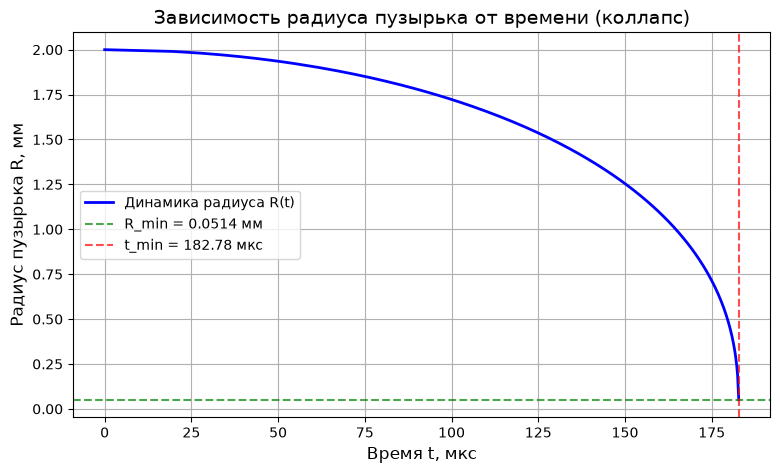

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.optimize import brentq

# Исходные данные для Задачи 1
p0 = 1.013e5  # атмосферное давление, Па
rho0 = 1000.0  # плотность воды, кг/м^3
R_initial = 2.0e-3  # начальный радиус, м
p_ratio = 0.005  # p_initial / p0
p_initial = p_ratio * p0
gamma = 1.4  # показатель адиабаты
T0 = 293.0  # начальная температура, К


# Функция W(R) для этапа коллапса
def W_collapse(R):
  term1 = (R_initial / R) ** 3 - 1.0
  term2 = (p_initial / p0) / (gamma - 1.0) * (
      (R_initial / R) ** 3 - (R_initial / R) ** (3 * gamma)
  )
  val = (2.0 * p0 / (3.0 * rho0)) * (term1 + term2)
  if val < 0:
    return 0.0
  return np.sqrt(val)

def integrand_collapse(R):
  w = W_collapse(R)
  if w == 0:
    return 0.0
  return 1.0 / w

# 1. Поиск минимального радиуса R_min
def equation_to_solve(R):
  term1 = (R_initial / R) ** 3 - 1.0
  term2 = (p_initial / p0) / (gamma - 1.0) * (
      (R_initial / R) ** 3 - (R_initial / R) ** (3 * gamma)
  )
  return term1 + term2


R_min = brentq(equation_to_solve, 1e-6 * R_initial, 0.999 * R_initial)
print(f"Минимальный радиус R_min: {R_min*1e6:.3f} мкм")

# 2. Расчет времени коллапса t_*
t_star, _ = quad(integrand_collapse, R_min, R_initial, limit=1000)
print(f"Время коллапса t_*: {t_star*1e6:.3f} мкс")

# 3. Расчет максимального давления и температуры
p_max = p_initial * (R_initial / R_min) ** (3 * gamma)
T_max = T0 * (R_initial / R_min) ** (3 * (gamma - 1))
print(f"Максимальное давление p_max: {p_max/1e9:.3f} ГПа (или {p_max/p0:.1f} атм)")
print(f"Максимальная температура T_max: {T_max:.1f} К")

# 4. Расчет точек для графика
R_values = np.linspace(R_min * 1.001, R_initial, 200)

# Первая ветвь: коллапс (от R_initial до R_min)
t_collapse = np.array([quad(integrand_collapse, r, R_initial)[0] for r in R_values])

# Объединяем в общие массивы для красивой отрисовки цикла
t_full = np.concatenate([t_collapse])
R_full = np.concatenate([R_values])


# # Вторая ветвь: отскок (симметричная во времени от t_star, с тем же диапазоном радиусов для демонстрации)
# t_bounce = t_star + (t_star - t_collapse[::-1])
# R_bounce = R_values[::-1]

# # Объединяем в общие массивы для красивой отрисовки цикла
# t_full = np.concatenate([t_collapse, t_bounce[1:]])
# R_full = np.concatenate([R_values, R_bounce[1:]])


# 5. Построение графиков
plt.figure(figsize=(9, 5))
plt.plot(
    t_full * 1e6, R_full * 1e3, "b-", lw=2, label="Динамика радиуса R(t)"
)

# Горизонтальная пунктирная линия для R_min
plt.axhline(
    R_min * 1e3,
    color="g",
    linestyle="--",
    alpha=0.7,
    label=f"R_min = {R_min*1e3:.4f} мм",
)

# Вертикальная пунктирная линия для t_star (t_min)
plt.axvline(
    t_star * 1e6,
    color="r",
    linestyle="--",
    alpha=0.7,
    label=f"t_min = {t_star*1e6:.2f} мкс",
)

plt.xlabel("Время t, мкс", fontsize=12)
plt.ylabel("Радиус пузырька R, мм", fontsize=12)
plt.title(
    "Зависимость радиуса пузырька от времени (коллапс)", fontsize=14
)
plt.legend()
plt.grid(True)
plt.show()

1. Резонансный радиус R_res для частоты 200 кГц: 15.827 мкм


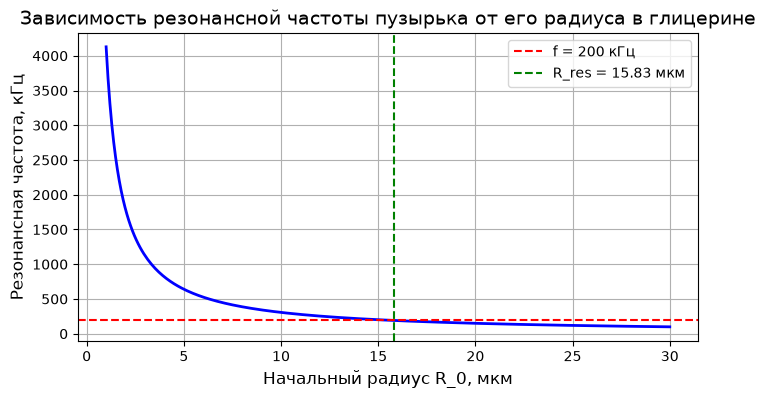

Точный порог Блейка P_B: -0.5306 атм


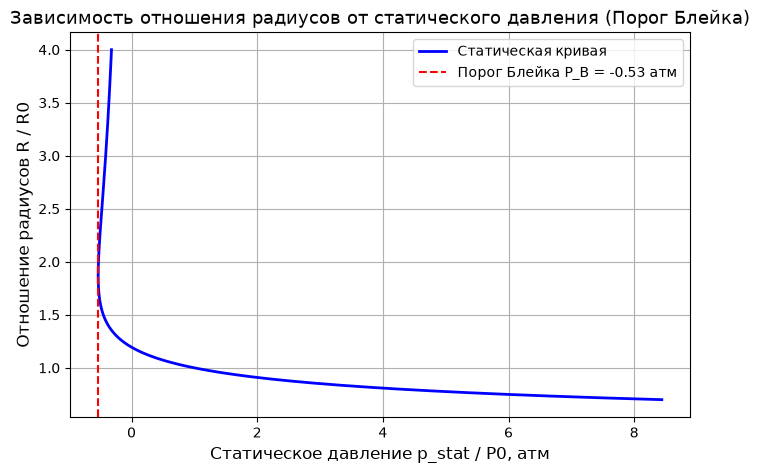

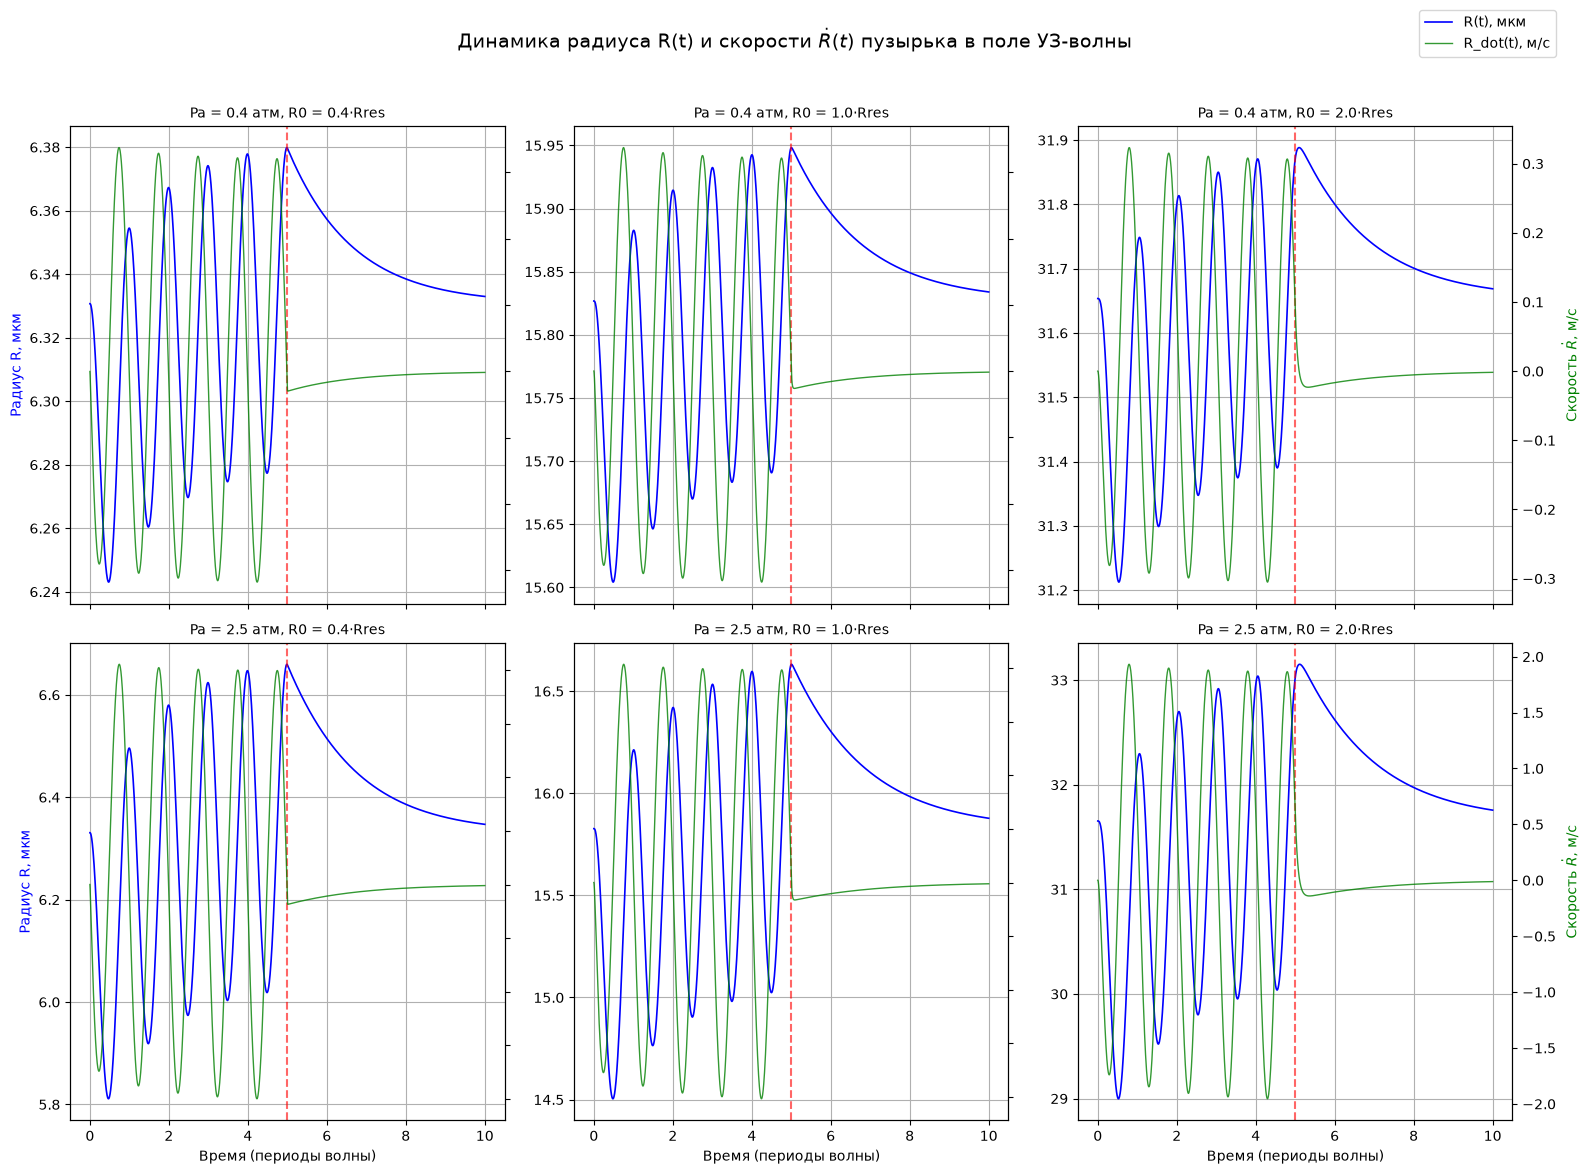

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

# --- ИСХОДНЫЕ ДАННЫЕ ДЛЯ ГЛИЦЕРИНА ---
rho = 1260.0  # плотность глицерина, кг/м^3
sigma = 0.066  # коэффициент поверхностного натяжения, Н/м
eta = 1.0  # динамическая вязкость, Па*с
P0 = 1.013e5  # атмосферное давление, Па (1 атм)
gamma = 1.4  # показатель адиабаты


# 1. РЕЗОНАНСНАЯ ЧАСТОТА И РАЗМЕР ПУЗЫРЬКА

def minnaert_freq(R0):
  omega = np.sqrt(
      (3.0 * gamma * (P0 + 2.0 * sigma / R0) - 2.0 * sigma / R0)
      / (rho * R0**2)
  )
  return omega / (2.0 * np.pi)  # частота в Гц


target_f = 200e3  # 200 кГц


def objective_f(R0):
  return abs(minnaert_freq(R0) - target_f)


res_opt = minimize_scalar(
    objective_f, bounds=(0.1e-6, 50e-6), method='bounded'
)
R_res = res_opt.x
print(f'1. Резонансный радиус R_res для частоты 200 кГц: {R_res*1e6:.3f} мкм')

R_range_freq = np.linspace(1e-6, 30e-6, 300)
f_range_khz = [minnaert_freq(r) / 1e3 for r in R_range_freq]

plt.figure(figsize=(8, 4))
plt.plot(R_range_freq * 1e6, f_range_khz, 'b', lw=2)
plt.axhline(200, color='r', linestyle='--', label='f = 200 кГц')
plt.axvline(
    R_res * 1e6, color='g', linestyle='--', label=f'R_res = {R_res*1e6:.2f} мкм'
)
plt.xlabel('Начальный радиус R_0, мкм', fontsize=12)
plt.ylabel('Резонансная частота, кГц', fontsize=12)
plt.title(
    'Зависимость резонансной частоты пузырька от его радиуса в глицерине',
    fontsize=14,
)
plt.legend()
plt.grid(True)
plt.show()


# 2. СТАТИЧЕСКОЕ ДАВЛЕНИЕ И ПОРОГ БЛЕЙКА

R0_blake = 1.0e-6  # начальный радиус 1 мкм


def p_stat(R, R0):
  p_gas = (P0 + 2.0 * sigma / R0) * (R0 / R) ** (3.0 * gamma)
  return p_gas - 2.0 * sigma / R


R_test = np.linspace(0.7e-6, 4.0e-6, 1000)
r_ratio_test = R_test / R0_blake
p_test_atm = np.array([p_stat(r, R0_blake) / P0 for r in R_test])

p_blake_atm = np.min(p_test_atm)
idx_min = np.argmin(p_test_atm)
R_crit_blake = R_test[idx_min]

print(f'Точный порог Блейка P_B: {p_blake_atm:.4f} атм')

plt.figure(figsize=(8, 5))
plt.plot(p_test_atm, r_ratio_test, 'b-', lw=2, label='Статическая кривая')
plt.axvline(
    p_blake_atm,
    color='r',
    linestyle='--',
    lw=1.5,
    label=f'Порог Блейка P_B = {p_blake_atm:.2f} атм',
)
plt.xlabel('Статическое давление p_stat / P0, атм', fontsize=12)
plt.ylabel('Отношение радиусов R / R0', fontsize=12)
plt.title(
    'Зависимость отношения радиусов от статического давления (Порог Блейка)',
    fontsize=13,
)
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


# 3. УРАВНЕНИЕ РЭЛЕЯ — ПЛЕССЕТА В ПОЛЕ УЗ-ВОЛНЫ
# (Расчет R(t) и производной R_dot(t))


def rayleigh_plesset(t, y, R0, Pa, omega, pulse_periods):
  R, R_dot = y
  if R <= 1e-9:
    return [0.0, 0.0]

  p_gas = (P0 + 2.0 * sigma / R0) * (R0 / R) ** (3.0 * gamma)

  T_period = 2.0 * np.pi / omega
  if t <= pulse_periods * T_period:
    P_t = Pa * np.sin(omega * t)
  else:
    P_t = 0.0

  numerator = (
      p_gas
      - P0
      - (2.0 * sigma / R)
      - (4.0 * eta * R_dot / R)
      - P_t
      - 1.5 * rho * R_dot**2
  )
  R_ddot = numerator / (rho * R)

  return [R_dot, R_ddot]


f_uw = 200e3  # 200 кГц[cite: 1]
omega = 2.0 * np.pi * f_uw
T_per = 2.0 * np.pi / omega
t_span = (0.0, 10.0 * T_per)  # расчет на 10 периодов[cite: 1]
t_eval = np.linspace(0.0, 10.0 * T_per, 2000)

r_ratios = [0.4, 1.0, 2.0]  # R0 / R_res[cite: 1]
pa_values = [0.4 * P0, 2.5 * P0]  # 0.4 атм и 2.5 атм[cite: 1]

# Строим сетку графиков для радиуса и скорости
fig, axes = plt.subplots(
    len(pa_values), len(r_ratios), figsize=(16, 12), sharex=True
)

for i, Pa in enumerate(pa_values):
  for j, ratio in enumerate(r_ratios):
    R0_current = ratio * R_res
    sol = solve_ivp(
        lambda t, y: rayleigh_plesset(t, y, R0_current, Pa, omega, 5),
        t_span,
        [R0_current, 0.0],
        t_eval=t_eval,
        method='RK45',
        rtol=1e-6,
        atol=1e-8,
    )

    t_periods = sol.t / T_per
    R_microns = sol.y[0] * 1e6
    R_dot_ms = sol.y[1]  # производная радиуса по времени (скорость, м/с)

    ax1 = axes[i, j]

    # График радиуса (левая ось Y)
    (line1,) = ax1.plot(
        t_periods, R_microns, 'b-', lw=1.2, label='R(t), мкм'
    )
    ax1.axvline(
        5.0, color='r', linestyle='--', alpha=0.6, label='Конец импульса'
    )
    ax1.grid(True)
    if j == 0:
      ax1.set_ylabel('Радиус R, мкм', color='b', fontsize=10)

    # Создаем вторую ось Y для производной (скорости изменения радиуса)
    ax2 = ax1.twinx()
    (line2,) = ax2.plot(
        t_periods, R_dot_ms, 'g-', lw=1.0, alpha=0.8, label='R_dot(t), м/с'
    )
    if j == len(r_ratios) - 1:
      ax2.set_ylabel('Скорость $\dot{R}$, м/с', color='g', fontsize=10)
    else:
      ax2.set_yticklabels([])

    ax1.set_title(
        f'Pa = {Pa/P0:.1f} атм, R0 = {ratio}·Rres',
        fontsize=10,
    )
    if i == len(pa_values) - 1:
      ax1.set_xlabel('Время (периоды волны)', fontsize=10)

# Добавляем общую легенду
lines = [line1, line2]
labels = [l.get_label() for l in lines]
fig.legend(lines, labels, loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.suptitle(
    'Динамика радиуса R(t) и скорости $\dot{R}(t)$ пузырька в поле УЗ-волны',
    fontsize=14,
    y=0.96,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()